In [1]:
import matplotlib.pyplot as plt
import tensorflow as tf
import seaborn as sns
import numpy as np
import os
import pandas as pd
from tensorflow.keras.datasets import cifar10

In [2]:
(x_train,y_train),(x_test,y_test)=tf.keras.datasets.cifar10.load_data()

In [3]:
x_train,x_test=x_train/255.0,x_test/255.0

In [4]:
labels=['automobile','aeroplane','bird','cat','deer','dog','frog','horse','ship','truck']

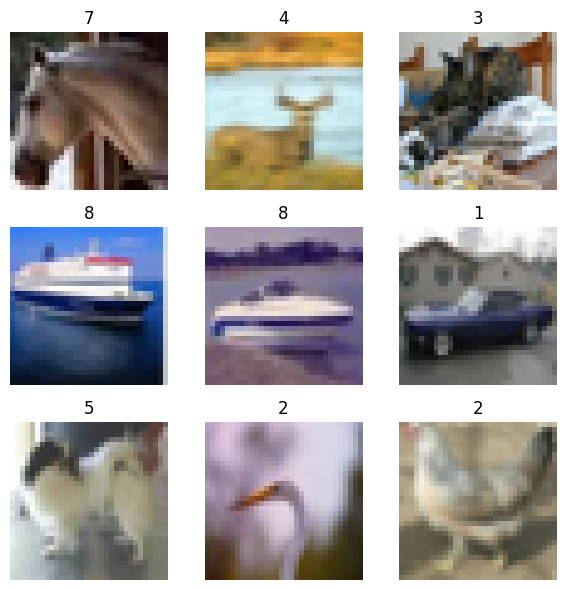

In [6]:
plt.figure(figsize=(6,6))
for i,idx in enumerate(np.random.choice(len(x_train),9,replace=False)):
    plt.subplot(3,3,i+1)
    plt.imshow(x_train[idx])
    plt.title(y_train[idx][0])
    plt.axis("off")
plt.tight_layout()
plt.show()
    

In [12]:
def create_model(use_dropout=False):
    layers=[
        tf.keras.layers.Flatten(input_shape=(32,32,3)),
        tf.keras.layers.Dense(128,activation='relu'),]
    if use_dropout:
        layers.append(tf.keras.layers.Dropout(0.2))
    layers.append(tf.keras.layers.Dense(32,activation='relu'))
    if use_dropout:
        layers.append(tf.keras.layers.Dropout(0.2))
    layers.append(tf.keras.layers.Dense(10,activation='softmax'))
    model=tf.keras.Sequential(layers)
    model.compile(
        optimizer='Adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'],)
    return model
    
        
                                

In [13]:
model_no_dropout=create_model(use_dropout=False)
model_dropout=create_model(use_dropout=True)
print("----Model Summary(Without Dropout)-----")
model_no_dropout.summary()
print("----Model Summary(With Dropout)-----")
model_dropout.summary()

----Model Summary(Without Dropout)-----


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_4 (Flatten)                  │ (None, 3072)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_12 (Dense)                     │ (None, 128)                 │         393,344 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_13 (Dense)                     │ (None, 32)                  │           4,128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_14 (Dense)                     │ (None, 10)                  │             330 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 397,802 (1.52 MB)

 Trainable params: 397,802 (1.52 MB)

...

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_5 (Flatten)                  │ (None, 3072)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_15 (Dense)                     │ (None, 128)                 │         393,344 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_16 (Dense)                     │ (None, 32)                  │           4,128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_17 (Dense)                     │ (None, 10)                  │             330 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 397,802 (1.52 MB)

 Trainable params: 397,802 (1.52 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
history_no_dropout=model_no_dropout.fit(
    x_train,y_train,batch_size=512,epochs=25,validation_data=(x_test,y_test))

history_dropout=model_dropout.fit(
    x_train,y_train,batch_size=512,epochs=25,validation_data=(x_test,y_test))

Epoch 1/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.4866 - loss: 1.4504 - val_accuracy: 0.4620 - val_loss: 1.5181
Epoch 2/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.4906 - loss: 1.4388 - val_accuracy: 0.4689 - val_loss: 1.5040
Epoch 3/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.4903 - loss: 1.4352 - val_accuracy: 0.4608 - val_loss: 1.5188
Epoch 4/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.4932 - loss: 1.4308 - val_accuracy: 0.4732 - val_loss: 1.4888
Epoch 5/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.4973 - loss: 1.4231 - val_accuracy: 0.4747 - val_loss: 1.4732
Epoch 6/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.4970 - loss: 1.4206 - val_accuracy: 0.4731 - val_loss: 1.4791
Epoch 7/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 0.4969 - loss: 1.4188 - val_accuracy: 0.4684 - val_loss: 1.4977
Epoch 8/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.5021 - loss: 1.4075 - val_accuracy: 0.4741 - v

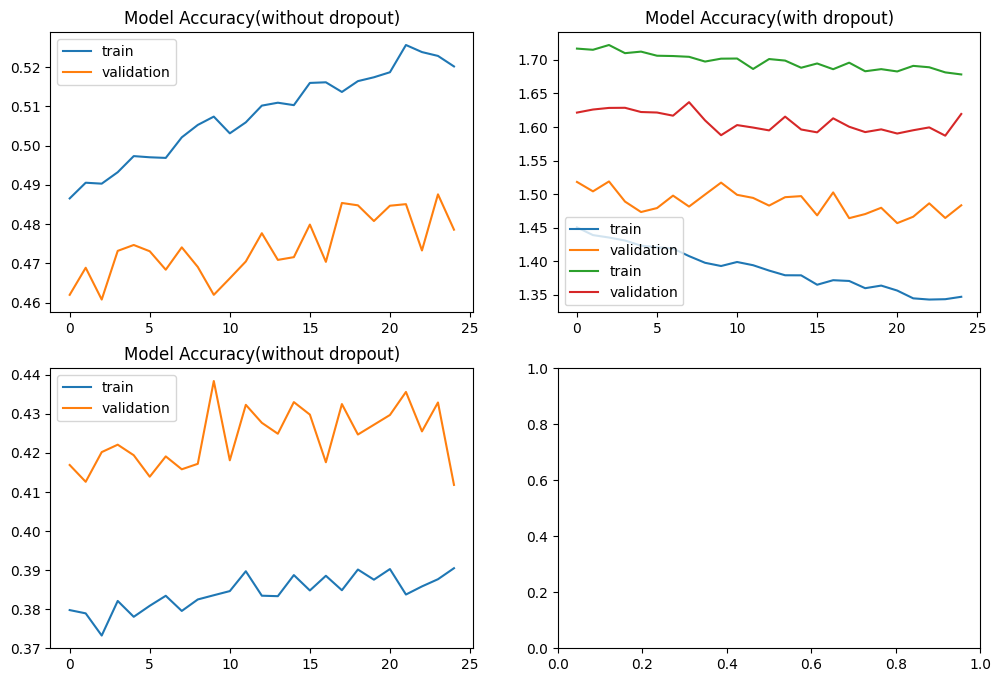

In [22]:
fig,axes=plt.subplots(2,2,figsize=(12,8))
axes[0,0].plot(history_no_dropout.history["accuracy"],label="train")
axes[0,0].plot(history_no_dropout.history["val_accuracy"],label="validation")
axes[0,0].set_title("Model Accuracy(without dropout)")
axes[0,0].legend()
axes[0,1].plot(history_no_dropout.history["loss"],label="train")
axes[0,1].plot(history_no_dropout.history["val_loss"],label="validation")
axes[0,1].set_title("Model Accuracy(with dropout)")
axes[0,1].legend()

axes[1,0].plot(history_dropout.history["accuracy"],label="train")
axes[1,0].plot(history_dropout.history["val_accuracy"],label="validation")
axes[1,0].set_title("Model Accuracy(without dropout)")
axes[1,0].legend()
axes[0,1].plot(history_dropout.history["loss"],label="train")
axes[0,1].plot(history_dropout.history["val_loss"],label="validation")
axes[0,1].set_title("Model Accuracy(with dropout)")
axes[0,1].legend()

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
              precision    recall  f1-score   support

  automobile       0.48      0.63      0.55      1000
   aeroplane       0.66      0.47      0.55      1000
        bird       0.37      0.30      0.33      1000
         cat       0.36      0.26      0.30      1000
        deer       0.50      0.29      0.37      1000
         dog       0.42      0.37      0.39      1000
        frog       0.46      0.65      0.54      1000
       horse       0.43      0.65      0.52      1000
        ship       0.59      0.62      0.61      1000
       truck       0.53      0.55      0.54      1000

    accuracy                           0.48     10000
   macro avg       0.48      0.48      0.47     10000
weighted avg       0.48      0.48      0.47     10000



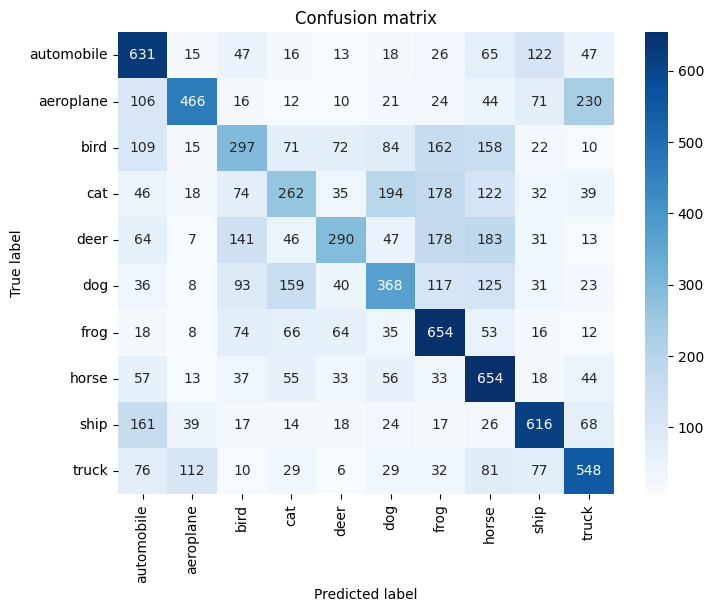

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
              precision    recall  f1-score   support

  automobile       0.49      0.47      0.48      1000
   aeroplane       0.70      0.30      0.42      1000
        bird       0.26      0.06      0.10      1000
         cat       0.28      0.26      0.27      1000
        deer       0.32      0.43      0.37      1000
         dog       0.41      0.28      0.34      1000
        frog       0.42      0.55      0.48      1000
       horse       0.39      0.59      0.47      1000
        ship       0.47      0.58      0.52      1000
       truck       0.44      0.60      0.50      1000

    accuracy                           0.41     10000
   macro avg       0.42      0.41      0.39     10000
weighted avg       0.42      0.41      0.39     10000



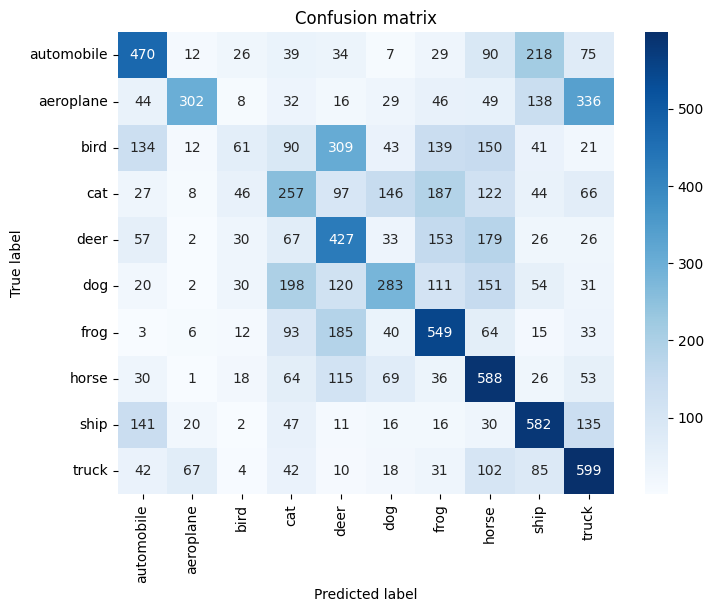

In [25]:
def evaluate_model(model,name):
    y_pred=np.argmax(model.predict(x_test),axis=-1)
    print(classification_report(y_test.flatten(),y_pred,target_names=labels))
    plt.figure(figsize=(8,6))
    sns.heatmap(
        confusion_matrix(y_test.flatten(),y_pred),
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=labels,
        yticklabels=labels,)
    plt.title("Confusion matrix")
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.show()
evaluate_model(model_no_dropout,"Without Dropout")
evaluate_model(model_dropout,"With Dropout")              
              
        
    

In [24]:
from sklearn.metrics import classification_report,confusion_matrix